# 031 — CatBoost com ponderação suave

Recupera CatBoost 029 selecionado (depth=4, learning_rate=0,1) e as restrições de recursos documentadas. Compara sem pesos e pesos de classe normalizados proporcionais a 1/√frequência, calculados só no treino. O limite é 1.000 iterações e early stopping 50. A seleção usa Macro F1 não ponderada; a métrica interna CatBoost é confirmada com sklearn. Ambas as versões são avaliadas na validação fixa sem a usar para seleção.

Nota de reprodução: a saída guardada do 029 selecionou 262 iterações/F1 interna 0,4718; a nova execução sem pesos selecionou 181/F1 interna 0,4625, embora depth, learning rate e restrições documentadas sejam os mesmos. Como o runner original não está disponível, a interpretação de ganhos absolutos face ao 029 histórico é limitada; a comparação sem pesos/ponderada nesta experiência é emparelhada.

A validação fixa é desenvolvimento, não teste independente. Kaggle fica em branco. Execução sequencial, CPU e uma thread; os checkpoints validam dados, preparação, configuração e versões.

031: resultados/checkpoints reutilizados após validação de dados, preparação, configuração e versões.


,variant,selected_iterations,catboost_best_macro_f1,sklearn_macro_f1,selection_seconds
0,sem_pesos,181,0.462479,0.462479,200.319018
1,inverse_sqrt,376,0.488735,0.488735,331.527115


Selecionada internamente: {'variant': 'inverse_sqrt', 'class_weights': [1.6367169952124478, 1.7967606075551161, 1.180588376140311, 1.212318092834287, 1.112841284046447, 0.926524291567972, 0.8042234360149392, 0.8028498680849474, 0.7836923193964779, 0.7404121510036796, 0.7232934788825025, 0.7309260519630135, 0.7452958311783415, 0.8220102716462921, 0.924425706106491, 1.0571212383667346], 'selected_iterations': 376, 'catboost_best_macro_f1': 0.4887345968282213, 'sklearn_macro_f1': 0.4887345968282213, 'internal_metrics': {'macro_f1': 0.4887345968282213, 'accuracy': 0.49544072948328266, 'per_class': [{'classe': 0, 'escalão': '15–17 anos', 'F1': 0.9230769230769231, 'recall': 0.96, 'support': 25}, {'classe': 1, 'escalão': '18–19 anos', 'F1': 0.37209302325581395, 'recall': 0.38095238095238093, 'support': 21}, {'classe': 2, 'escalão': '20–24 anos', 'F1': 0.5656565656565656, 'recall': 0.5833333333333334, 'support': 48}, {'classe': 3, 'escalão': '25–29 anos', 'F1': 0.40816326530612246, 'recall': 0

,sem_pesos,inverse_sqrt
1,"{'classe': 1, 'escalão': '18–19 anos', 'F1': 0...","{'classe': 1, 'escalão': '18–19 anos', 'F1': 0..."
6,"{'classe': 6, 'escalão': '40–44 anos', 'F1': 0...","{'classe': 6, 'escalão': '40–44 anos', 'F1': 0..."
13,"{'classe': 13, 'escalão': '75–79 anos', 'F1': ...","{'classe': 13, 'escalão': '75–79 anos', 'F1': ..."


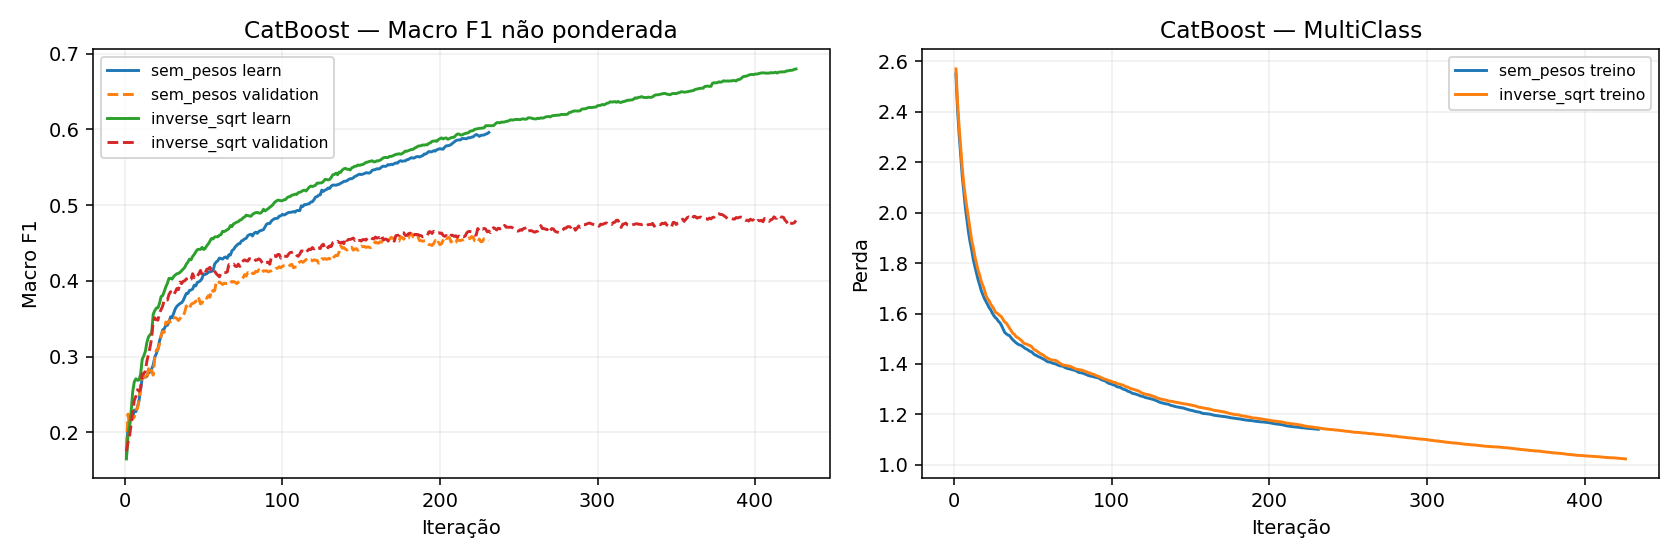

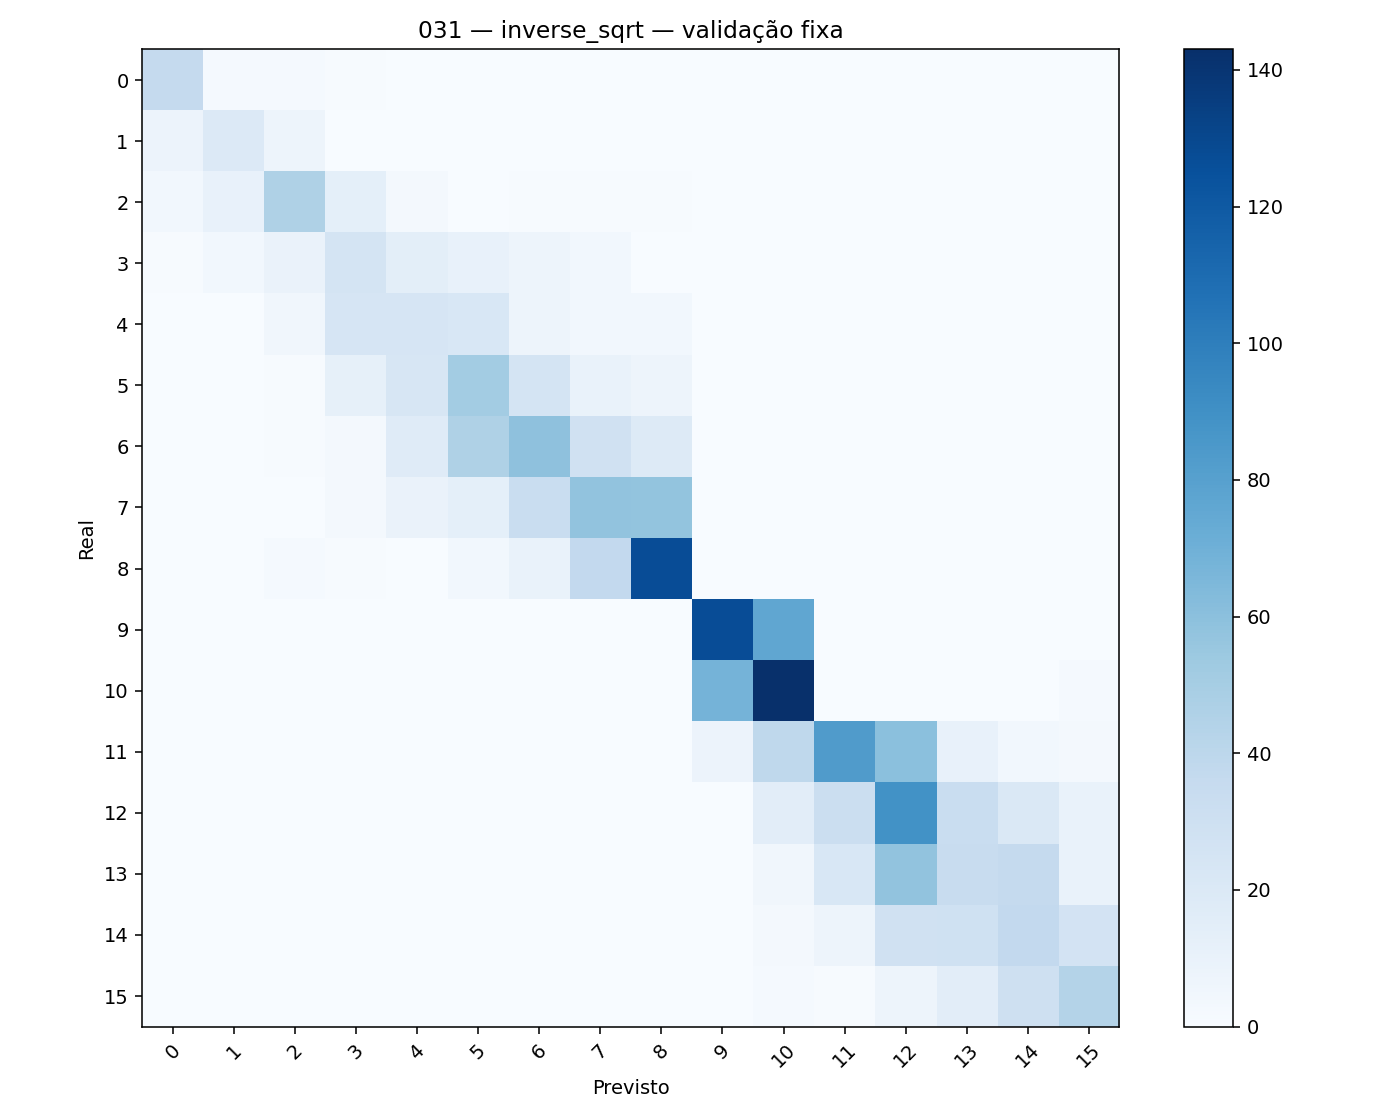

CSV: {'path': 'submissions/submission_031_catboost_ponderacao_suave.csv', 'duplicate_of': [], 'differences': {'submission_016_xgboost_mlp015.csv': 1194, 'submission_019_ensemble_pesos.csv': 1196, 'submission_025_xgboost_mlp_dropout.csv': 1175, 'submission_028_ensemble_features_dominio.csv': 1181, 'submission_029_catboost.csv': 695}, 'reason': None}
/Users/eduardaferreira/daa-kaggle-2026-2027/reports/experiments_030_032.md


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
import pandas as pd

root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'src' / 'experiments_030_032.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Executa este notebook na pasta notebooks/ deste projeto.')
sys.path.insert(0, str(root))
from src.experiments_030_032 import run_031, write_final_report

result = run_031()
display(pd.DataFrame([{k: row[k] for k in ['variant', 'selected_iterations', 'catboost_best_macro_f1', 'sklearn_macro_f1', 'selection_seconds']} for row in result['candidates']]))
print('Selecionada internamente:', result['selected_internally'])
for label, metrics in result['fixed_metrics_both_variants'].items():
    print(label, 'treino:', metrics['train']['macro_f1'], 'validação fixa:', metrics['validation']['macro_f1'])
display(pd.DataFrame(result['key_class_comparison']).T)
display(Image(filename=str(root / result['curves'])))
display(Image(filename=str(root / result['confusion_matrix'])))
print('CSV:', result['submission'])
print(write_final_report())

## Conclusão e decisão

- Data: 14/11
- Pontuação Kaggle:0.47
- Conclusão: a ponderação suave venceu internamente (F1 0,4887) e na validação fixa (0,4587 vs. 0,4450). Classe 1 ganhou F1/recall (+0,183/+0,294); classes 6 e 13 perderam (-0,040/-0,122 e -0,019/-0,018). O CSV é distinto, mas exploratório: fica abaixo do melhor controlo 025/028 (0,4615), e a reprodução histórica de 029 não é exata.
- Melhorias: avaliar a estabilidade dos ganhos por classe, sobretudo o custo nas classes 6 e 13.